# Point-source folding with broadened kernels

`UnbinnedThreeMLPointSourceResponseTrapz` folds the spectrum with kernels of the IRF
broadened over energy cells (`BroadenedIRFCache`), using the same nodes and the same
attitude samples (interval midpoints) for the density of each event and for the expected
counts `S`. Each kernel piece is normalized by the IRF to its selected area, so the density
integrates over the selected data space to exactly `S`, for any grid of cells.

This notebook checks, on the real `hist_simple` response and the real attitude of a 3 h
window, how accurate the folding is: per-event densities and `S` against a brute-force
integral over the photon energy with the original IRF. It also shows the grid chosen for a
Crab-like spectrum and what the cache costs.

The closure test (events generated from the IRF, fit with background) comes with the event
generators and the analytic background in the next PR.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.time import Time
from astromodels import Powerlaw, PointSource

from cosipy.data_io.EmCDSUnbinnedData import (EmCDSEventDataInSCFrameFromArrays,
                                              TimeTagEmCDSEventDataInSCFrameFromArrays)
from cosipy.event_selection.energy_selection import EnergySelector
from cosipy.response.broadened_irf_cache import BroadenedIRFCache
from cosipy.response.photon_types import PhotonListWithDirectionAndEnergyInSCFrame
from cosipy.response.relative_irf_hist import IRFRelativeHistUnpolarized
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.threeml.psr_fixed_ei import UnbinnedThreeMLPointSourceResponseTrapz

# threeML (imported by cosipy) sets a non-interactive backend without a display
%matplotlib inline


WARNING TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [2]:
data_path = Path('/home/user/dc4data')
irf_file = data_path / 'ResponseContinuum.area.relative.nonsparse_smoothing1p0.h5'

selection = EnergySelector([200., 5000.] * u.keV)
tstart, tstop = Time('2028-03-23 10:36:00'), Time('2028-03-23 13:36:00')

sc = SpacecraftHistory.open(data_path / 'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits')
sc = sc.select_interval(tstart, tstop)

spectrum = Powerlaw(index=-2.2, K=2.5e-6, piv=1000.)
spectrum.K.unit = 1 / u.cm ** 2 / u.s / u.keV
spectrum.piv.unit = u.keV
source = PointSource('Crab', l=184.56, b=-5.78, spectral_shape=spectrum)

Crab events from the DC4 mock data in the window, inside the selection (the true Crab-only
events; the background doesn't matter for this check).

In [3]:
z = np.load(data_path / 'crabfull' / 'crab_all.npz')
t = Time(z['TimeTags'], format='unix')
keep = (t >= tstart) & (t < tstop) & (z['Energies'] >= 200) & (z['Energies'] < 5000)
t = t[keep]
data = TimeTagEmCDSEventDataInSCFrameFromArrays(t.jd1, t.jd2, z['Energies'][keep], z['Chi local'][keep],
                                                np.pi / 2 - z['Psi local'][keep], z['Phi'][keep])
print(data.nevents, 'events')

3018 events


## The cache and the grid

The cache is built from the IRF without selections; the selections are applied when the
kernels are evaluated. Without a file (the default) the kernels are computed when the
folding needs them, one cell at a time, only for the `NuLambda` pixels of the source track,
and not kept. A file can be given to keep them (`BroadenedIRFCache(irf, filename)`).

In [4]:
irf = IRFRelativeHistUnpolarized.from_h5(irf_file, selections=selection)
cache = BroadenedIRFCache(IRFRelativeHistUnpolarized.from_h5(irf_file), energy_range_keV=(100., 10_000.))

cells = UnbinnedThreeMLPointSourceResponseTrapz.cells_for(source, cache, accuracy=1e-3)
print(len(cells), 'cells, levels', sorted({level for level, _ in cells}))

16 cells, levels [3]


In [5]:
t0 = time.time()
psr = UnbinnedThreeMLPointSourceResponseTrapz(data, irf, sc, cache, cells, offset=None)
psr.set_source(source)
psr.init_cache()
print(f'kernels and responses for this source position: {time.time() - t0:.0f} s')

t0 = time.time()
spectrum.index.value = -2.0
psr.expected_counts(), psr.expectation_density()
spectrum.index.value = -2.2
print(f'new spectral parameters: {time.time() - t0:.3f} s')

S = psr.expected_counts()
s = np.asarray(psr.expectation_density())
print(f'S = {S:.1f} expected counts; {data.nevents} Crab events observed')


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



...


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



kernels and responses for this source position: 132 s
new spectral parameters: 0.003 s
S = 1583.3 expected counts; 3018 Crab events observed


## Brute force

The same quantities, integrating over the photon energy with the original IRF on a fine
grid (4000 points over 100 keV - 10 MeV), at the same attitude samples: the midpoint of each
15 s interval, for the events in it and for `S`. Here for a random subset of the events.

In [6]:
energy = np.geomspace(100, 10_000, 4001)
de = np.gradient(energy)
flux = spectrum(energy)

obstime = sc.obstime
mid = sc.interp(obstime[:-1] + (obstime[1:] - obstime[:-1]) / 2)
coord = source.position.sky_coord
sc_coord = mid.get_target_in_sc_frame(coord)
lon, lat = np.asarray(sc_coord.lon.rad), np.asarray(sc_coord.lat.rad)
visible = ~np.asarray(mid.get_earth_occ(coord))
livetime = sc.livetime.to_value(u.s)
livetime_ratio = livetime / sc.intervals_duration.to_value(u.s)

t0 = time.time()
S_brute = 0.
for j in range(lon.size):
    if visible[j] and livetime[j] > 0:
        photons = PhotonListWithDirectionAndEnergyInSCFrame(np.full(energy.size, lon[j]),
                                                            np.full(energy.size, lat[j]), energy)
        S_brute += livetime[j] * np.sum(np.asarray(irf.effective_area_cm2(photons)) * flux * de)
print(f'S: folding {S:.2f}, brute force {S_brute:.2f}, ratio {S / S_brute:.5f} ({time.time() - t0:.0f} s)')


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



...


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide



S: folding 1583.32, brute force 1594.96, ratio 0.99271 (8 s)


In [7]:
rng = np.random.default_rng(0)
subset = np.sort(rng.choice(data.nevents, 300, replace=False))
interval = np.clip(np.searchsorted(obstime.utc.unix, data.time.utc.unix[subset], side='right') - 1, 0, lon.size - 1)

n = subset.size
photons = PhotonListWithDirectionAndEnergyInSCFrame(np.repeat(lon[interval], energy.size),
                                                    np.repeat(lat[interval], energy.size), np.tile(energy, n))
events = EmCDSEventDataInSCFrameFromArrays(*(np.repeat(np.asarray(a)[subset], energy.size)
                                             for a in (data.energy_keV, data.scattered_lon_rad_sc,
                                                       data.scattered_lat_rad_sc, data.scattering_angle_rad)))
diff = np.asarray(irf.differential_effective_area_cm2(photons, events)).reshape(n, energy.size)
s_brute = (livetime_ratio * visible)[interval] * (diff @ (flux * de))

ratio = s[subset] / s_brute
print(f'per-event density / brute force: median {np.median(ratio):.4f}, '
      f'5-95% {np.percentile(ratio, 5):.4f} - {np.percentile(ratio, 95):.4f}, '
      f'density-weighted |error| {np.sum(np.abs(s[subset] - s_brute)) / np.sum(s_brute):.4f}')

per-event density / brute force: median 0.9883, 5-95% 0.9652 - 1.0281, density-weighted |error| 0.0161


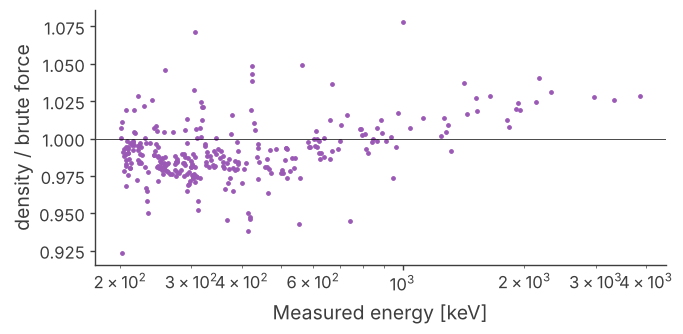

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(np.asarray(data.energy_keV)[subset], ratio, s=6)
ax.axhline(1, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel('Measured energy [keV]')
ax.set_ylabel('density / brute force')
fig.tight_layout()

The folding uses `len(cells)` nodes for every event, instead of hundreds of `Ei` points per
event. The per-event error is the binning of the kernels in `Epsilon'` (it goes down as the
square of `max_epsilon_step`) plus the interpolation of `F / w` between nodes; neither
changes the normalization, which is exact by construction.